In [1]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score,accuracy_score
from sklearn.preprocessing import LabelEncoder

In [2]:
df = pd.read_csv(r"C:\Users\Admin\Downloads\retail_customer_ml_practice.csv")

In [3]:
df.head(5)

,Customer_ID,Age,Gender,City,Annual_Income,Membership,Tenure_Months,Monthly_Store_Visits,Product_Category,Discount_Percent,Payment_Method,Satisfaction_Rating,Purchase_Date,Purchase_Amount,Repeat_Purchase
0,CUST0001,22.0,Male,Mumbai,77797.86,Silver,40,2,Clothing,5,UPI,4.0,2025-10-26,2519.94,No
1,CUST0002,55.0,Male,Aurangabad,53647.36,Silver,64,5,Clothing,15,Cash,4.0,2025-10-13,2429.38,Yes
2,CUST0003,49.0,Female,Mumbai,62453.99,Basic,23,3,Home,10,UPI,3.0,2024-05-04,1858.74,Yes
3,CUST0004,39.0,Male,Aurangabad,50977.90,Silver,106,4,Clothing,25,UPI,4.0,2025-03-29,3683.32,Yes
4,CUST0005,38.0,Female,Nagpur,48932.66,Basic,88,3,Home,10,UPI,2.0,2025-09-02,3226.68,Yes


In [4]:
df.tail()

,Customer_ID,Age,Gender,City,Annual_Income,Membership,Tenure_Months,Monthly_Store_Visits,Product_Category,Discount_Percent,Payment_Method,Satisfaction_Rating,Purchase_Date,Purchase_Amount,Repeat_Purchase
1007,CUST0095,61.0,Female,Aurangabad,25813.20,Basic,70,3,Home,25,Card,3.0,2025-08-08,2114.04,Yes
1008,CUST0488,43.0,Female,Pune,68638.44,Basic,15,3,Clothing,5,Net Banking,3.0,2024-09-18,2006.23,Yes
1009,CUST0171,NaN,Male,Nagpur,48864.89,Basic,42,3,Electronics,10,UPI,5.0,2024-08-15,3019.86,Yes
1010,CUST0025,55.0,Male,Dhule,42217.08,Silver,100,4,Sports,25,Net Banking,5.0,2024-04-05,2568.33,Yes
1011,CUST0243,22.0,Female,Nagpur,25060.50,Basic,50,5,Sports,15,Cash,3.0,2025-10-17,2163.70,Yes


In [5]:
df.sample(10)

,Customer_ID,Age,Gender,City,Annual_Income,Membership,Tenure_Months,Monthly_Store_Visits,Product_Category,Discount_Percent,Payment_Method,Satisfaction_Rating,Purchase_Date,Purchase_Amount,Repeat_Purchase
226,CUST0227,56.0,Female,Mumbai,62053.88,Silver,17,3,Clothing,15,Card,3.0,2024-08-30,2857.55,No
562,CUST0563,41.0,Female,Dhule,53834.67,Basic,111,6,Clothing,10,UPI,5.0,2025-01-06,2428.46,Yes
656,CUST0657,54.0,Female,Nashik,52670.10,Silver,35,3,Home,15,Cash,2.0,2025-07-15,2523.36,Yes
62,CUST0063,35.0,Female,Dhule,48773.92,Gold,85,5,Beauty,0,Cash,5.0,2025-11-09,3613.64,Yes
853,CUST0854,29.0,Male,Nagpur,59415.49,Gold,112,3,Electronics,0,UPI,NaN,2024-10-29,2862.43,Yes
329,CUST0330,44.0,Male,Aurangabad,48362.50,Basic,29,4,Clothing,25,UPI,4.0,2025-08-26,2972.26,Yes
112,CUST0113,44.0,Male,Dhule,22268.34,Silver,9,4,Electronics,10,UPI,3.0,2025-04-30,2935.92,No
994,CUST0995,43.0,Male,Mumbai,49069.62,Basic,83,7,Clothing,15,Card,4.0,2024-06-18,2782.47,Yes
201,CUST0202,61.0,Male,Dhule,74531.05,Basic,63,4,Home,25,UPI,4.0,2025-11-07,2610.13,Yes
436,CUST0437,45.0,Female,Nashik,61529.44,Silver,50,5,Electronics,5,UPI,2.0,2025-09-27,3099.42,Yes


In [6]:
df.shape

(1012, 15)

In [7]:
df.columns

Index(['Customer_ID', 'Age', 'Gender', 'City', 'Annual_Income', 'Membership',
       'Tenure_Months', 'Monthly_Store_Visits', 'Product_Category',
       'Discount_Percent', 'Payment_Method', 'Satisfaction_Rating',
       'Purchase_Date', 'Purchase_Amount', 'Repeat_Purchase'],
      dtype='object')

In [8]:
df.dtypes

Customer_ID              object
Age                     float64
Gender                   object
City                     object
Annual_Income           float64
Membership               object
Tenure_Months             int64
Monthly_Store_Visits      int64
Product_Category         object
Discount_Percent          int64
Payment_Method           object
Satisfaction_Rating     float64
Purchase_Date            object
Purchase_Amount         float64
Repeat_Purchase          object
dtype: object

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1012 entries, 0 to 1011
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Customer_ID           1012 non-null   object 
 1   Age                   971 non-null    float64
 2   Gender                992 non-null    object 
 3   City                  1012 non-null   object 
 4   Annual_Income         962 non-null    float64
 5   Membership            981 non-null    object 
 6   Tenure_Months         1012 non-null   int64  
 7   Monthly_Store_Visits  1012 non-null   int64  
 8   Product_Category      1012 non-null   object 
 9   Discount_Percent      1012 non-null   int64  
 10  Payment_Method        987 non-null    object 
 11  Satisfaction_Rating   972 non-null    float64
 12  Purchase_Date         1012 non-null   object 
 13  Purchase_Amount       1012 non-null   float64
 14  Repeat_Purchase       1012 non-null   object 
dtypes: float64(4), int64(

In [10]:
df.describe()

,Age,Annual_Income,Tenure_Months,Monthly_Store_Visits,Discount_Percent,Satisfaction_Rating,Purchase_Amount
count,971.000000,962.000000,1012.000000,1012.000000,1012.000000,972.000000,1012.000000
mean,41.752832,51563.727121,60.181818,4.933794,11.798419,3.684156,2927.193617
std,13.783027,18097.895277,34.253528,1.985746,7.670055,0.903156,637.183163
min,18.000000,12000.000000,1.000000,1.000000,0.000000,1.000000,936.440000
25%,30.000000,39074.582500,29.000000,4.000000,5.000000,3.000000,2470.967500
50%,42.000000,51941.025000,60.000000,5.000000,10.000000,4.000000,2948.795000
75%,54.000000,63401.710000,90.000000,6.000000,15.000000,4.000000,3377.650000
max,65.000000,109219.370000,120.000000,15.000000,25.000000,5.000000,4793.900000


In [11]:
df.describe(include="object")

,Customer_ID,Gender,City,Membership,Product_Category,Payment_Method,Purchase_Date,Repeat_Purchase
count,1012,992,1012,981,1012,987,1012,1012
unique,1000,3,6,4,5,4,532,2
top,CUST0272,Female,Mumbai,Basic,Sports,Card,2025-06-25,Yes
freq,2,507,178,385,215,254,7,775


In [12]:
df.isna().sum()

Customer_ID              0
Age                     41
Gender                  20
City                     0
Annual_Income           50
Membership              31
Tenure_Months            0
Monthly_Store_Visits     0
Product_Category         0
Discount_Percent         0
Payment_Method          25
Satisfaction_Rating     40
Purchase_Date            0
Purchase_Amount          0
Repeat_Purchase          0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(12)

In [14]:
df.drop_duplicates(inplace=True)

In [15]:
df.describe(include="object")

,Customer_ID,Gender,City,Membership,Product_Category,Payment_Method,Purchase_Date,Repeat_Purchase
count,1000,980,1000,970,1000,975,1000,1000
unique,1000,3,6,4,5,4,532,2
top,CUST1000,Female,Mumbai,Basic,Sports,Card,2025-06-25,Yes
freq,1,503,177,379,211,251,7,763


In [16]:
df["City"].value_counts()

City
Mumbai        177
Dhule         175
Pune          169
Nagpur        168
Nashik        164
Aurangabad    147
Name: count, dtype: int64

In [17]:
df.groupby("City")["Customer_ID"].count()

City
Aurangabad    147
Dhule         175
Mumbai        177
Nagpur        168
Nashik        164
Pune          169
Name: Customer_ID, dtype: int64

In [18]:
df["Gender"].value_counts().head(2)

Gender
Female    503
Male      452
Name: count, dtype: int64

In [19]:
df.rename(columns={"Annual_Income":"Income"},inplace=True)

In [20]:
df

,Customer_ID,Age,Gender,City,Income,Membership,Tenure_Months,Monthly_Store_Visits,Product_Category,Discount_Percent,Payment_Method,Satisfaction_Rating,Purchase_Date,Purchase_Amount,Repeat_Purchase
0,CUST0001,22.0,Male,Mumbai,77797.86,Silver,40,2,Clothing,5,UPI,4.0,2025-10-26,2519.94,No
1,CUST0002,55.0,Male,Aurangabad,53647.36,Silver,64,5,Clothing,15,Cash,4.0,2025-10-13,2429.38,Yes
2,CUST0003,49.0,Female,Mumbai,62453.99,Basic,23,3,Home,10,UPI,3.0,2024-05-04,1858.74,Yes
3,CUST0004,39.0,Male,Aurangabad,50977.90,Silver,106,4,Clothing,25,UPI,4.0,2025-03-29,3683.32,Yes
4,CUST0005,38.0,Female,Nagpur,48932.66,Basic,88,3,Home,10,UPI,2.0,2025-09-02,3226.68,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,CUST0996,48.0,Male,Aurangabad,89727.98,Platinum,74,3,Sports,15,UPI,4.0,2024-09-10,3503.57,Yes
996,CUST0997,43.0,Female,Dhule,25771.52,Gold,37,8,Home,20,UPI,5.0,2025-09-20,3060.96,Yes
997,CUST0998,35.0,Male,Nashik,44967.80,Silver,45,5,Electronics,0,Card,4.0,2024-03-16,2351.76,No
998,CUST0999,64.0,NaN,Dhule,82705.35,Silver,40,8,Home,20,Cash,4.0,2024-03-20,3516.19,Yes


In [21]:
df[["Age","City","Income"]]

,Age,City,Income
0,22.0,Mumbai,77797.86
1,55.0,Aurangabad,53647.36
2,49.0,Mumbai,62453.99
3,39.0,Aurangabad,50977.90
4,38.0,Nagpur,48932.66
...,...,...,...
995,48.0,Aurangabad,89727.98
996,43.0,Dhule,25771.52
997,35.0,Nashik,44967.80
998,64.0,Dhule,82705.35


In [22]:
df.iloc[0:21:1,0:5:1]

,Customer_ID,Age,Gender,City,Income
0,CUST0001,22.0,Male,Mumbai,77797.86
1,CUST0002,55.0,Male,Aurangabad,53647.36
2,CUST0003,49.0,Female,Mumbai,62453.99
3,CUST0004,39.0,Male,Aurangabad,50977.90
4,CUST0005,38.0,Female,Nagpur,48932.66
5,CUST0006,59.0,Male,Nagpur,37969.32
6,CUST0007,22.0,Female,Dhule,59745.42
7,CUST0008,51.0,Male,Nagpur,36672.33
8,CUST0009,27.0,Male,Pune,63980.53
9,CUST0010,22.0,Female,Aurangabad,71535.17


In [23]:
df.sort_values("Income",ascending=False)

,Customer_ID,Age,Gender,City,Income,Membership,Tenure_Months,Monthly_Store_Visits,Product_Category,Discount_Percent,Payment_Method,Satisfaction_Rating,Purchase_Date,Purchase_Amount,Repeat_Purchase
365,CUST0366,42.0,Male,Nagpur,109219.37,Basic,77,9,Beauty,0,Card,4.0,2025-11-02,3555.32,Yes
596,CUST0597,45.0,Female,Mumbai,102565.80,Silver,10,4,Electronics,5,Card,4.0,2024-02-01,3629.22,Yes
857,CUST0858,20.0,Male,Nashik,100793.42,Basic,111,5,Electronics,5,Net Banking,4.0,2024-05-25,3507.01,Yes
150,CUST0151,59.0,Male,Nashik,97887.90,Basic,81,2,Beauty,15,Card,4.0,2025-04-05,2799.57,Yes
685,CUST0686,56.0,Female,Pune,96233.63,Basic,64,4,Electronics,25,Cash,4.0,2024-05-02,4118.15,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
931,CUST0932,NaN,Male,Dhule,NaN,Gold,31,3,Sports,5,UPI,3.0,2025-08-06,1832.19,No
967,CUST0968,33.0,Male,Aurangabad,NaN,Basic,14,6,Electronics,15,Card,3.0,2025-09-20,2161.01,No
969,CUST0970,19.0,Male,Pune,NaN,Platinum,107,8,Beauty,5,Card,4.0,2024-09-08,3970.33,Yes
977,CUST0978,45.0,Female,Dhule,NaN,Basic,83,8,Sports,5,NaN,1.0,2024-04-17,3753.43,Yes


In [24]:
df[df["Age"]>30].shape

(709, 15)

In [25]:
df[df["Income"]>60000].shape

(302, 15)

In [26]:
df[df["Purchase_Amount"]>3000].shape

(462, 15)

In [27]:
df[df["City"]=="Pune"]

,Customer_ID,Age,Gender,City,Income,Membership,Tenure_Months,Monthly_Store_Visits,Product_Category,Discount_Percent,Payment_Method,Satisfaction_Rating,Purchase_Date,Purchase_Amount,Repeat_Purchase
8,CUST0009,27.0,Male,Pune,63980.53,Basic,101,7,Beauty,0,UPI,4.0,2024-11-26,3370.15,Yes
20,CUST0021,42.0,Male,Pune,68113.33,Basic,46,5,Beauty,20,UPI,5.0,2025-05-13,2617.50,Yes
22,CUST0023,26.0,Male,Pune,24954.94,Gold,85,3,Home,20,Cash,3.0,2025-12-24,2764.33,Yes
35,CUST0036,21.0,Male,Pune,64029.87,Basic,98,7,Electronics,5,Card,2.0,2024-08-17,3438.53,Yes
36,CUST0037,59.0,Female,Pune,39609.30,Basic,25,5,Clothing,25,Cash,4.0,2024-08-05,2075.84,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
971,CUST0972,38.0,Male,Pune,50105.97,Basic,59,7,Clothing,10,Card,3.0,2024-12-12,3310.31,Yes
973,CUST0974,40.0,Male,Pune,78409.26,Silver,17,3,Clothing,15,Net Banking,4.0,2025-09-11,2911.09,Yes
981,CUST0982,51.0,Female,Pune,36632.33,Basic,35,5,Home,5,Net Banking,3.0,2024-09-10,3358.03,Yes
987,CUST0988,33.0,Female,Pune,26311.54,Silver,50,4,Beauty,10,Card,3.0,2025-02-27,2170.52,Yes


In [28]:
df[df["Membership"]=="Gold"]

,Customer_ID,Age,Gender,City,Income,Membership,Tenure_Months,Monthly_Store_Visits,Product_Category,Discount_Percent,Payment_Method,Satisfaction_Rating,Purchase_Date,Purchase_Amount,Repeat_Purchase
6,CUST0007,22.0,Female,Dhule,59745.42,Gold,21,4,Clothing,15,UPI,4.0,2025-04-24,2683.67,Yes
14,CUST0015,52.0,Male,Nashik,68839.85,Gold,97,4,Sports,20,UPI,3.0,2024-09-03,3335.33,Yes
16,CUST0017,42.0,Female,Mumbai,45959.07,Gold,47,6,Home,5,Cash,4.0,2024-01-08,2660.94,Yes
22,CUST0023,26.0,Male,Pune,24954.94,Gold,85,3,Home,20,Cash,3.0,2025-12-24,2764.33,Yes
27,CUST0028,57.0,Female,Nashik,41927.70,Gold,9,10,Electronics,20,Cash,3.0,2025-03-22,3830.88,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
982,CUST0983,44.0,Female,Aurangabad,60274.71,Gold,55,4,Beauty,5,Net Banking,3.0,2024-06-02,2757.90,No
983,CUST0984,49.0,Male,Dhule,69793.96,Gold,17,4,Beauty,15,UPI,4.0,2025-07-16,3228.10,Yes
986,CUST0987,47.0,Male,Nashik,27515.35,Gold,83,2,Clothing,15,Net Banking,4.0,2024-04-22,1937.75,No
990,CUST0991,34.0,Female,Pune,72250.79,Gold,33,3,Home,25,Cash,3.0,2025-11-07,2583.71,Yes


In [29]:
df[df["Age"].between(25,40)].sample(20)

,Customer_ID,Age,Gender,City,Income,Membership,Tenure_Months,Monthly_Store_Visits,Product_Category,Discount_Percent,Payment_Method,Satisfaction_Rating,Purchase_Date,Purchase_Amount,Repeat_Purchase
486,CUST0487,34.0,Male,Mumbai,38640.54,Gold,23,8,Sports,15,UPI,5.0,2025-07-03,3262.85,Yes
911,CUST0912,26.0,Male,Nagpur,42233.96,Gold,56,4,Home,5,UPI,4.0,2025-10-02,2935.64,Yes
622,CUST0623,25.0,Female,Aurangabad,61353.89,Basic,62,9,Sports,0,UPI,3.0,2024-05-22,3018.84,Yes
566,CUST0567,28.0,Female,Dhule,61766.70,Basic,75,6,Beauty,10,Cash,4.0,2024-12-11,3256.55,Yes
142,CUST0143,31.0,Female,Mumbai,NaN,Silver,76,3,Sports,5,NaN,3.0,2024-04-16,2743.36,No
606,CUST0607,33.0,Female,Mumbai,24214.75,Basic,120,6,Electronics,0,Net Banking,3.0,2025-09-09,3088.97,Yes
280,CUST0281,31.0,Male,Aurangabad,63436.68,Basic,95,3,Home,10,Net Banking,4.0,2024-11-12,2598.69,Yes
563,CUST0564,26.0,Female,Nashik,38278.18,NaN,17,3,Home,0,UPI,3.0,2024-03-22,2326.00,No
406,CUST0407,38.0,Male,Aurangabad,44235.89,Silver,73,6,Clothing,20,Net Banking,4.0,2025-08-07,2972.47,Yes
200,CUST0201,35.0,Female,Nashik,63251.53,Silver,108,5,Electronics,20,Cash,5.0,2024-05-24,3417.33,Yes


In [30]:
df[df["Income"].between(30000,40000)].sample(10)

,Customer_ID,Age,Gender,City,Income,Membership,Tenure_Months,Monthly_Store_Visits,Product_Category,Discount_Percent,Payment_Method,Satisfaction_Rating,Purchase_Date,Purchase_Amount,Repeat_Purchase
785,CUST0786,46.0,Male,Dhule,36950.97,Basic,66,5,Electronics,10,Card,3.0,2025-09-30,2472.57,Yes
839,CUST0840,61.0,Male,Mumbai,38310.84,Silver,27,5,Home,15,Net Banking,4.0,2024-10-06,3912.78,Yes
863,CUST0864,55.0,Female,Nagpur,33416.85,Gold,92,6,Home,10,Cash,5.0,2025-10-20,3991.30,Yes
181,CUST0182,25.0,Male,Dhule,35756.38,Silver,94,3,Beauty,5,NaN,4.0,2025-10-30,2424.63,Yes
102,CUST0103,56.0,Female,Nagpur,32701.61,Basic,92,4,Clothing,15,UPI,3.0,2025-02-01,2222.29,No
563,CUST0564,26.0,Female,Nashik,38278.18,NaN,17,3,Home,0,UPI,3.0,2024-03-22,2326.00,No
172,CUST0173,55.0,Other,Mumbai,32132.67,Basic,68,2,Home,20,Card,3.0,2024-04-04,1862.36,Yes
238,CUST0239,32.0,Female,Mumbai,33598.95,Silver,11,2,Electronics,20,Cash,3.0,2024-02-14,2280.81,Yes
716,CUST0717,42.0,Male,Nagpur,35322.40,Platinum,10,8,Sports,25,UPI,4.0,2024-08-14,3253.07,Yes
590,CUST0591,56.0,Female,Nashik,31936.89,NaN,5,5,Electronics,10,UPI,3.0,2024-05-03,2734.74,No


In [31]:
df[df["City"].isin({"Mumbai","Pune"})].sample(20)

,Customer_ID,Age,Gender,City,Income,Membership,Tenure_Months,Monthly_Store_Visits,Product_Category,Discount_Percent,Payment_Method,Satisfaction_Rating,Purchase_Date,Purchase_Amount,Repeat_Purchase
885,CUST0886,53.0,Male,Mumbai,31714.22,Basic,19,6,Sports,5,Net Banking,5.0,2024-11-18,2803.84,Yes
876,CUST0877,43.0,Female,Mumbai,42872.10,Gold,8,8,Home,0,Cash,NaN,2024-05-07,2581.48,No
364,CUST0365,23.0,Female,Pune,58578.54,Gold,43,3,Home,0,Cash,4.0,2024-10-01,2873.01,Yes
861,CUST0862,62.0,Male,Pune,NaN,Basic,2,6,Sports,15,Cash,4.0,2024-03-10,3039.54,Yes
66,CUST0067,61.0,Female,Pune,33846.35,Platinum,109,6,Home,10,Cash,5.0,2024-08-23,4370.82,Yes
82,CUST0083,25.0,Female,Pune,38220.37,Basic,53,8,Home,20,Cash,4.0,2024-04-21,3132.99,Yes
486,CUST0487,34.0,Male,Mumbai,38640.54,Gold,23,8,Sports,15,UPI,5.0,2025-07-03,3262.85,Yes
519,CUST0520,46.0,Female,Pune,50932.91,NaN,21,5,Electronics,10,Cash,4.0,2025-02-13,3604.66,Yes
166,CUST0167,33.0,Female,Pune,20847.91,Gold,51,8,Clothing,25,Card,2.0,2024-08-26,3667.43,No
417,CUST0418,23.0,Female,Pune,60619.76,Platinum,48,7,Clothing,20,UPI,4.0,2025-03-15,3544.39,Yes


In [32]:
df[(df["Membership"]=="Platinum") & (df["Income"]>80000)]

,Customer_ID,Age,Gender,City,Income,Membership,Tenure_Months,Monthly_Store_Visits,Product_Category,Discount_Percent,Payment_Method,Satisfaction_Rating,Purchase_Date,Purchase_Amount,Repeat_Purchase
301,CUST0302,57.0,Female,Mumbai,84356.10,Platinum,75,9,Clothing,25,Card,2.0,2025-03-22,4300.65,Yes
359,CUST0360,53.0,Male,Nashik,86291.08,Platinum,111,3,Home,5,UPI,3.0,2025-11-13,3511.19,Yes
995,CUST0996,48.0,Male,Aurangabad,89727.98,Platinum,74,3,Sports,15,UPI,4.0,2024-09-10,3503.57,Yes


In [33]:
df["Income"].max()

np.float64(109219.37)

In [34]:
df[df["Satisfaction_Rating"]==5]

,Customer_ID,Age,Gender,City,Income,Membership,Tenure_Months,Monthly_Store_Visits,Product_Category,Discount_Percent,Payment_Method,Satisfaction_Rating,Purchase_Date,Purchase_Amount,Repeat_Purchase
7,CUST0008,51.0,Male,Nagpur,36672.33,Silver,85,2,Sports,10,Card,5.0,2025-07-18,2370.99,Yes
17,CUST0018,24.0,Female,Nagpur,16165.38,Basic,33,3,Electronics,25,UPI,5.0,2025-12-07,2191.40,Yes
20,CUST0021,42.0,Male,Pune,68113.33,Basic,46,5,Beauty,20,UPI,5.0,2025-05-13,2617.50,Yes
24,CUST0025,55.0,Male,Dhule,42217.08,Silver,100,4,Sports,25,Net Banking,5.0,2024-04-05,2568.33,Yes
31,CUST0032,NaN,Female,Dhule,53790.59,Platinum,94,5,Electronics,0,UPI,5.0,2024-03-05,3902.66,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
957,CUST0958,48.0,Female,Dhule,29548.29,Basic,63,7,Beauty,20,Card,5.0,2025-06-11,2939.33,Yes
965,CUST0966,46.0,Male,Nashik,93864.04,Silver,79,9,Sports,10,Net Banking,5.0,2025-08-25,4535.37,Yes
980,CUST0981,46.0,Male,Aurangabad,38957.00,Basic,66,4,Electronics,5,Cash,5.0,2025-01-15,3196.65,Yes
996,CUST0997,43.0,Female,Dhule,25771.52,Gold,37,8,Home,20,UPI,5.0,2025-09-20,3060.96,Yes


In [35]:
df[df["Repeat_Purchase"].duplicated()].shape

(998, 15)

In [36]:
df[df["Payment_Method"]=="UPI"]

,Customer_ID,Age,Gender,City,Income,Membership,Tenure_Months,Monthly_Store_Visits,Product_Category,Discount_Percent,Payment_Method,Satisfaction_Rating,Purchase_Date,Purchase_Amount,Repeat_Purchase
0,CUST0001,22.0,Male,Mumbai,77797.86,Silver,40,2,Clothing,5,UPI,4.0,2025-10-26,2519.94,No
2,CUST0003,49.0,Female,Mumbai,62453.99,Basic,23,3,Home,10,UPI,3.0,2024-05-04,1858.74,Yes
3,CUST0004,39.0,Male,Aurangabad,50977.90,Silver,106,4,Clothing,25,UPI,4.0,2025-03-29,3683.32,Yes
4,CUST0005,38.0,Female,Nagpur,48932.66,Basic,88,3,Home,10,UPI,2.0,2025-09-02,3226.68,Yes
6,CUST0007,22.0,Female,Dhule,59745.42,Gold,21,4,Clothing,15,UPI,4.0,2025-04-24,2683.67,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
983,CUST0984,49.0,Male,Dhule,69793.96,Gold,17,4,Beauty,15,UPI,4.0,2025-07-16,3228.10,Yes
984,CUST0985,46.0,Female,Nashik,52724.62,Platinum,26,5,Clothing,5,UPI,3.0,2024-01-29,3049.53,Yes
985,CUST0986,49.0,Male,Nashik,28844.92,Basic,53,7,Electronics,10,UPI,3.0,2025-09-30,2991.59,Yes
995,CUST0996,48.0,Male,Aurangabad,89727.98,Platinum,74,3,Sports,15,UPI,4.0,2024-09-10,3503.57,Yes


In [37]:
df[df["Discount_Percent"]>15]

,Customer_ID,Age,Gender,City,Income,Membership,Tenure_Months,Monthly_Store_Visits,Product_Category,Discount_Percent,Payment_Method,Satisfaction_Rating,Purchase_Date,Purchase_Amount,Repeat_Purchase
3,CUST0004,39.0,Male,Aurangabad,50977.90,Silver,106,4,Clothing,25,UPI,4.0,2025-03-29,3683.32,Yes
14,CUST0015,52.0,Male,Nashik,68839.85,Gold,97,4,Sports,20,UPI,3.0,2024-09-03,3335.33,Yes
17,CUST0018,24.0,Female,Nagpur,16165.38,Basic,33,3,Electronics,25,UPI,5.0,2025-12-07,2191.40,Yes
20,CUST0021,42.0,Male,Pune,68113.33,Basic,46,5,Beauty,20,UPI,5.0,2025-05-13,2617.50,Yes
22,CUST0023,26.0,Male,Pune,24954.94,Gold,85,3,Home,20,Cash,3.0,2025-12-24,2764.33,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
968,CUST0969,62.0,Male,Nagpur,41322.04,Basic,43,4,Beauty,20,UPI,3.0,2024-03-16,1549.20,No
990,CUST0991,34.0,Female,Pune,72250.79,Gold,33,3,Home,25,Cash,3.0,2025-11-07,2583.71,Yes
993,CUST0994,38.0,Other,Mumbai,48566.31,Silver,4,12,Electronics,25,Net Banking,2.0,2025-09-17,3829.05,Yes
996,CUST0997,43.0,Female,Dhule,25771.52,Gold,37,8,Home,20,UPI,5.0,2025-09-20,3060.96,Yes


In [38]:
df[df["Age"].isna()].shape

(40, 15)

In [39]:
df[df["Income"].notnull()].shape

(950, 15)

In [40]:
df.isna().sum()

Customer_ID              0
Age                     40
Gender                  20
City                     0
Income                  50
Membership              30
Tenure_Months            0
Monthly_Store_Visits     0
Product_Category         0
Discount_Percent         0
Payment_Method          25
Satisfaction_Rating     40
Purchase_Date            0
Purchase_Amount          0
Repeat_Purchase          0
dtype: int64

In [41]:
df[df["Satisfaction_Rating"].between(3,5)].sample(20)

,Customer_ID,Age,Gender,City,Income,Membership,Tenure_Months,Monthly_Store_Visits,Product_Category,Discount_Percent,Payment_Method,Satisfaction_Rating,Purchase_Date,Purchase_Amount,Repeat_Purchase
695,CUST0696,30.0,Female,Mumbai,38284.46,Gold,64,1,Home,5,Cash,4.0,2025-03-12,2583.19,Yes
2,CUST0003,49.0,Female,Mumbai,62453.99,Basic,23,3,Home,10,UPI,3.0,2024-05-04,1858.74,Yes
20,CUST0021,42.0,Male,Pune,68113.33,Basic,46,5,Beauty,20,UPI,5.0,2025-05-13,2617.50,Yes
799,CUST0800,39.0,Female,Mumbai,73485.13,Silver,60,4,Beauty,25,Cash,3.0,2024-03-07,2814.99,No
478,CUST0479,49.0,Male,Nagpur,59344.65,Gold,100,7,Electronics,0,Card,3.0,2025-09-13,4203.12,Yes
906,CUST0907,37.0,Female,Dhule,32441.78,Basic,117,6,Beauty,0,Card,4.0,2025-09-27,2534.66,Yes
327,CUST0328,19.0,Male,Dhule,46256.08,Basic,15,3,Beauty,0,Card,4.0,2024-02-10,2674.57,Yes
358,CUST0359,22.0,Female,Pune,45953.09,Basic,98,7,Electronics,10,Card,3.0,2025-02-20,3494.04,No
589,CUST0590,58.0,Female,Dhule,48456.06,Basic,66,5,Clothing,10,Net Banking,3.0,2024-03-27,2178.55,Yes
875,CUST0876,42.0,Female,Mumbai,45228.18,Basic,102,4,Beauty,15,Cash,5.0,2025-02-17,1956.81,Yes


In [42]:
df[(df["City"]=="Nashik") & (df["Membership"]=="Silver")]

,Customer_ID,Age,Gender,City,Income,Membership,Tenure_Months,Monthly_Store_Visits,Product_Category,Discount_Percent,Payment_Method,Satisfaction_Rating,Purchase_Date,Purchase_Amount,Repeat_Purchase
10,CUST0011,43.0,Female,Nashik,58597.57,Silver,91,4,Clothing,10,Net Banking,4.0,2025-04-11,2028.39,Yes
38,CUST0039,31.0,Other,Nashik,81320.87,Silver,53,4,Beauty,20,Net Banking,3.0,2025-02-23,3414.41,Yes
117,CUST0118,24.0,Female,Nashik,56349.87,Silver,105,6,Electronics,10,Net Banking,4.0,2025-11-09,3956.39,Yes
134,CUST0135,56.0,Male,Nashik,28912.58,Silver,74,8,Electronics,10,UPI,3.0,2024-02-28,3245.09,No
135,CUST0136,32.0,Female,Nashik,64848.76,Silver,36,6,Home,15,Net Banking,5.0,2025-12-16,3569.01,Yes
177,CUST0178,25.0,Male,Nashik,73825.34,Silver,52,5,Sports,10,Card,5.0,2025-12-17,3251.71,No
200,CUST0201,35.0,Female,Nashik,63251.53,Silver,108,5,Electronics,20,Cash,5.0,2024-05-24,3417.33,Yes
210,CUST0211,30.0,Male,Nashik,47576.29,Silver,19,9,Electronics,15,UPI,5.0,2024-11-02,3157.56,Yes
236,CUST0237,49.0,Female,Nashik,64343.48,Silver,120,5,Beauty,15,Cash,5.0,2025-09-23,2902.18,Yes
251,CUST0252,41.0,Male,Nashik,61877.30,Silver,35,4,Beauty,0,UPI,5.0,2025-06-04,1840.62,No


In [43]:
df[df["Income"]<df["Income"].mean()].sample(4)

,Customer_ID,Age,Gender,City,Income,Membership,Tenure_Months,Monthly_Store_Visits,Product_Category,Discount_Percent,Payment_Method,Satisfaction_Rating,Purchase_Date,Purchase_Amount,Repeat_Purchase
534,CUST0535,45.0,Male,Mumbai,33621.19,Basic,78,6,Electronics,25,Net Banking,2.0,2025-05-31,2365.44,No
902,CUST0903,28.0,Female,Pune,49036.28,Silver,16,7,Clothing,20,Card,4.0,2025-11-21,2610.30,Yes
407,CUST0408,24.0,Female,Nashik,12000.00,Silver,60,5,Clothing,20,Cash,3.0,2024-08-31,2370.18,No
605,CUST0606,43.0,Male,Nashik,26834.03,Basic,73,4,Beauty,5,NaN,5.0,2025-06-18,1598.79,No


In [44]:
df["Income"].mean()

np.float64(51708.499421052635)

In [45]:
df.sort_values("Income",ascending=False).head(10)

,Customer_ID,Age,Gender,City,Income,Membership,Tenure_Months,Monthly_Store_Visits,Product_Category,Discount_Percent,Payment_Method,Satisfaction_Rating,Purchase_Date,Purchase_Amount,Repeat_Purchase
365,CUST0366,42.0,Male,Nagpur,109219.37,Basic,77,9,Beauty,0,Card,4.0,2025-11-02,3555.32,Yes
596,CUST0597,45.0,Female,Mumbai,102565.80,Silver,10,4,Electronics,5,Card,4.0,2024-02-01,3629.22,Yes
857,CUST0858,20.0,Male,Nashik,100793.42,Basic,111,5,Electronics,5,Net Banking,4.0,2024-05-25,3507.01,Yes
150,CUST0151,59.0,Male,Nashik,97887.90,Basic,81,2,Beauty,15,Card,4.0,2025-04-05,2799.57,Yes
685,CUST0686,56.0,Female,Pune,96233.63,Basic,64,4,Electronics,25,Cash,4.0,2024-05-02,4118.15,Yes
572,CUST0573,31.0,Male,Dhule,96012.34,Gold,91,3,Electronics,10,UPI,1.0,2024-11-04,3980.98,No
25,CUST0026,48.0,Female,Nagpur,95567.47,Silver,85,3,Electronics,25,UPI,4.0,2025-03-19,3083.56,Yes
195,CUST0196,22.0,Male,Dhule,94886.84,Basic,120,7,Beauty,15,Card,5.0,2025-06-10,3931.88,Yes
965,CUST0966,46.0,Male,Nashik,93864.04,Silver,79,9,Sports,10,Net Banking,5.0,2025-08-25,4535.37,Yes
864,CUST0865,58.0,Female,Dhule,93577.20,Gold,86,6,Home,15,Cash,4.0,2025-01-20,4162.05,Yes


In [46]:
df.isna().mean()

Customer_ID             0.000
Age                     0.040
Gender                  0.020
City                    0.000
Income                  0.050
Membership              0.030
Tenure_Months           0.000
Monthly_Store_Visits    0.000
Product_Category        0.000
Discount_Percent        0.000
Payment_Method          0.025
Satisfaction_Rating     0.040
Purchase_Date           0.000
Purchase_Amount         0.000
Repeat_Purchase         0.000
dtype: float64

In [47]:
df["Age"] = df["Age"].fillna(df["Age"].median())

In [48]:
df["Income"] = df["Income"].fillna(df["Income"].mean())

In [49]:
df["Gender"] = df["Gender"].fillna(df["Gender"].mode()[0])

In [50]:
df["Membership"] = df["Membership"].fillna(df["Membership"].mode()[0])

In [51]:
df.isna().sum()

Customer_ID              0
Age                      0
Gender                   0
City                     0
Income                   0
Membership               0
Tenure_Months            0
Monthly_Store_Visits     0
Product_Category         0
Discount_Percent         0
Payment_Method          25
Satisfaction_Rating     40
Purchase_Date            0
Purchase_Amount          0
Repeat_Purchase          0
dtype: int64

In [52]:
df[df["Customer_ID"].duplicated()]

,Customer_ID,Age,Gender,City,Income,Membership,Tenure_Months,Monthly_Store_Visits,Product_Category,Discount_Percent,Payment_Method,Satisfaction_Rating,Purchase_Date,Purchase_Amount,Repeat_Purchase


In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Customer_ID           1000 non-null   object 
 1   Age                   1000 non-null   float64
 2   Gender                1000 non-null   object 
 3   City                  1000 non-null   object 
 4   Income                1000 non-null   float64
 5   Membership            1000 non-null   object 
 6   Tenure_Months         1000 non-null   int64  
 7   Monthly_Store_Visits  1000 non-null   int64  
 8   Product_Category      1000 non-null   object 
 9   Discount_Percent      1000 non-null   int64  
 10  Payment_Method        975 non-null    object 
 11  Satisfaction_Rating   960 non-null    float64
 12  Purchase_Date         1000 non-null   object 
 13  Purchase_Amount       1000 non-null   float64
 14  Repeat_Purchase       1000 non-null   object 
dtypes: float64(4), int64(3), ob

In [54]:
df["Purchase_Date"] = pd.to_datetime(df["Purchase_Date"],format="mixed")

In [55]:
df["Purchase_Date"].dt.day

0      26
1      13
2       4
3      29
4       2
       ..
995    10
996    20
997    16
998    20
999     8
Name: Purchase_Date, Length: 1000, dtype: int32

In [56]:
df["Purchase_Date"].dt.day

0      26
1      13
2       4
3      29
4       2
       ..
995    10
996    20
997    16
998    20
999     8
Name: Purchase_Date, Length: 1000, dtype: int32

In [57]:
df["Age_Group"] = ""

In [58]:
df["Age_Group"] = df["Age"].apply(lambda x:x=="Junior Customer" if x<20 else "Senior Customer")

In [59]:
df["Age_Group"].value_counts()

Age_Group
Senior Customer    966
False               34
Name: count, dtype: int64

In [60]:
df.loc[df["Age"]<20].shape

(34, 16)

In [61]:
df.loc[df["Age"]<20,"Age_Group"]="Junior"

In [62]:
# df["Income_Category"]=""
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Customer_ID           1000 non-null   object        
 1   Age                   1000 non-null   float64       
 2   Gender                1000 non-null   object        
 3   City                  1000 non-null   object        
 4   Income                1000 non-null   float64       
 5   Membership            1000 non-null   object        
 6   Tenure_Months         1000 non-null   int64         
 7   Monthly_Store_Visits  1000 non-null   int64         
 8   Product_Category      1000 non-null   object        
 9   Discount_Percent      1000 non-null   int64         
 10  Payment_Method        975 non-null    object        
 11  Satisfaction_Rating   960 non-null    float64       
 12  Purchase_Date         1000 non-null   datetime64[ns]
 13  Purchase_Amount       10

In [63]:
df.loc[(df["Income"]<20000),"Income_Category"]="Low"

In [64]:
df["Income_Category"].value_counts()

Income_Category
Low    42
Name: count, dtype: int64

In [65]:
df["Gender"].str.upper().sample(10)

887    FEMALE
730      MALE
25     FEMALE
270    FEMALE
26     FEMALE
763    FEMALE
4      FEMALE
60       MALE
230    FEMALE
333    FEMALE
Name: Gender, dtype: object

In [66]:
df["Gender"].value_counts()

Gender
Female    523
Male      452
Other      25
Name: count, dtype: int64

In [126]:
df

,Customer_ID,Age,Gender,City,Income,Membership,Tenure_Months,Monthly_Store_Visits,Product_Category,Discount_Percent,Payment_Method,Satisfaction_Rating,Purchase_Date,Purchase_Amount,Repeat_Purchase,Age_Group,Income_Category,Purchase_Month
15,CUST0016,55.0,Male,Aurangabad,19034.69,Basic,18,5,Beauty,10,Net Banking,2.0,2025-11-28,1976.65,Yes,Senior Customer,Low,November
17,CUST0018,24.0,Female,Nagpur,16165.38,Basic,33,3,Electronics,25,UPI,5.0,2025-12-07,2191.40,Yes,Senior Customer,Low,December
23,CUST0024,62.0,Female,Nagpur,12000.00,Silver,67,2,Sports,15,Cash,4.0,2025-02-07,1901.95,No,Senior Customer,Low,February
57,CUST0058,25.0,Male,Dhule,12000.00,Basic,33,3,Beauty,15,Cash,3.0,2024-03-11,1907.54,Yes,Senior Customer,Low,March
99,CUST0100,24.0,Male,Mumbai,12000.00,Platinum,49,5,Beauty,10,UPI,3.0,2024-11-04,2494.69,No,Senior Customer,Low,November
148,CUST0149,57.0,Male,Nagpur,12000.00,Gold,1,7,Electronics,5,Cash,3.0,2025-09-18,3313.21,No,Senior Customer,Low,September
152,CUST0153,62.0,Male,Aurangabad,17136.92,Gold,89,5,Electronics,10,Net Banking,5.0,2025-12-24,3282.21,Yes,Senior Customer,Low,December
188,CUST0189,29.0,Female,Nashik,12000.00,Basic,101,2,Sports,20,Card,3.0,2025-10-03,2425.14,No,Senior Customer,Low,October
212,CUST0213,55.0,Male,Aurangabad,12000.00,Basic,29,5,Electronics,10,Net Banking,3.0,2025-06-21,2651.67,Yes,Senior Customer,Low,June
215,CUST0216,31.0,Female,Mumbai,12000.00,Silver,24,6,Beauty,10,UPI,4.0,2024-01-09,1994.97,Yes,Senior Customer,Low,January


In [68]:
# Gender	City	Membership	Product_Category	Payment_Method	Repeat_Purchase	Age_Group	Income_Category
df["Gender"] = df["Gender"].str.strip()
df["City"] = df["City"].str.strip()
df["Membership"] = df["Membership"].str.strip()
df["Product_Category"] = df["Product_Category"].str.strip()
df["Payment_Method"]= df["Payment_Method"].str.strip()

In [69]:
df["Repeat_Purchase"].value_counts()

Repeat_Purchase
Yes    763
No     237
Name: count, dtype: int64

In [70]:
df["Gender_value_convert"] = le.fit_transform(df["Gender"])
# le = LabelEncoder()

NameError: name 'le' is not defined

In [ ]:
df["Gender_value_convert"]

In [ ]:
df.drop(columns="Gender_value_convert",inplace=True)

In [ ]:
df.isna().sum()

In [ ]:
df["Payment_Method"] = df["Payment_Method"].fillna(df["Payment_Method"].mode()[0])

In [ ]:
df["Satisfaction_Rating"] = df["Satisfaction_Rating"].fillna(df["Satisfaction_Rating"].mode()[0])

In [ ]:
df11 = df.to_csv(r"C:\Users\Admin\Downloads\retail_customer__deep_ml_practice.csv")

In [71]:
df.groupby("City")["Income"].mean()

City
Aurangabad    50000.102750
Dhule         54103.825160
Mumbai        50695.009246
Nagpur        48068.179255
Nashik        54734.447604
Pune          52457.957132
Name: Income, dtype: float64

In [75]:
df.groupby("Product_Category")["Income"].sum()

Product_Category
Beauty         1.020440e+07
Clothing       1.053735e+07
Electronics    9.759839e+06
Home           1.010304e+07
Sports         1.110386e+07
Name: Income, dtype: float64

In [76]:
df.groupby("Membership").Income.mean()

Membership
Basic       51588.878938
Gold        51173.897168
Platinum    50963.902053
Silver      52432.178999
Name: Income, dtype: float64

In [78]:
df.groupby("City")["Income"].max()

City
Aurangabad     93069.39
Dhule          96012.34
Mumbai        102565.80
Nagpur        109219.37
Nashik        100793.42
Pune           96233.63
Name: Income, dtype: float64

In [79]:
df.groupby("Membership")["Age"].min()

Membership
Basic       18.0
Gold        18.0
Platinum    19.0
Silver      18.0
Name: Age, dtype: float64

In [81]:
df.groupby("Product_Category")["Customer_ID"].count()

Product_Category
Beauty         200
Clothing       205
Electronics    188
Home           196
Sports         211
Name: Customer_ID, dtype: int64

In [82]:
df.groupby("Gender")["Satisfaction_Rating"].mean()

Gender
Female    3.629191
Male      3.746512
Other     3.608696
Name: Satisfaction_Rating, dtype: float64

In [84]:
df.groupby("Payment_Method")["Income"].mean()

Payment_Method
Card           52476.336427
Cash           50852.449774
Net Banking    52442.574394
UPI            51344.373830
Name: Income, dtype: float64

In [85]:
df.groupby("City")["Income"].sum().head(3)

City
Aurangabad    7.350015e+06
Dhule         9.468169e+06
Mumbai        8.973017e+06
Name: Income, dtype: float64

In [87]:
df["City"].value_counts().head()

City
Mumbai    177
Dhule     175
Pune      169
Nagpur    168
Nashik    164
Name: count, dtype: int64

In [90]:
pd.DataFrame(df.groupby(["City","Membership"])["Income"].mean())

Income
City       Membership              
Aurangabad Basic       51552.562671
           Gold        47519.276337
           Platinum    48875.174615
           Silver      48798.003082
Dhule      Basic       52779.826852
           Gold        59817.865447
           Platinum    47912.534500
           Silver      54658.917607
Mumbai     Basic       50386.027337
           Gold        48989.378732
           Platinum    48511.366214
           Silver      52655.801569
Nagpur     Basic       47058.720946
           Gold        48111.204706
           Platinum    46522.637428
           Silver      49665.738857
Nashik     Basic       54399.451504
           Gold        53645.254985
           Platinum    61422.468000
           Silver      54703.284760
Pune       Basic       52909.794589
           Gold        47774.395316
           Platinum    55435.138040
           Silver      53171.584353

In [93]:
df[["Annual_Amount","Income"]].corr()

KeyError: "['Annual_Amount'] not in index"

In [94]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Customer_ID           1000 non-null   object        
 1   Age                   1000 non-null   float64       
 2   Gender                1000 non-null   object        
 3   City                  1000 non-null   object        
 4   Income                1000 non-null   float64       
 5   Membership            1000 non-null   object        
 6   Tenure_Months         1000 non-null   int64         
 7   Monthly_Store_Visits  1000 non-null   int64         
 8   Product_Category      1000 non-null   object        
 9   Discount_Percent      1000 non-null   int64         
 10  Payment_Method        975 non-null    object        
 11  Satisfaction_Rating   960 non-null    float64       
 12  Purchase_Date         1000 non-null   datetime64[ns]
 13  Purchase_Amount       10

In [95]:
df["Income"].mean()

np.float64(51708.499421052635)

In [98]:
df["Purchase_Month"]=df["Purchase_Date"].dt.month_name()

In [99]:
df.groupby("Purchase_Month")["Income"].mean()

Purchase_Month
April        51606.739636
August       50749.684836
December     52597.318355
February     52221.930619
January      51026.355891
July         50842.155182
June         52307.073279
March        50175.121777
May          52351.522310
November     53351.668194
October      50394.942145
September    53263.443504
Name: Income, dtype: float64

In [105]:
df.pivot_table(index="Product_Category",columns="City",values="Income")

City,Aurangabad,Dhule,Mumbai,Nagpur,Nashik,Pune
Product_Category,,,,,,
Beauty,50964.284942,53581.505295,46620.912482,48236.077008,54593.089983,51025.341395
Clothing,49210.492105,53087.326748,54160.767822,46523.951935,52610.824333,52510.603143
Electronics,46768.768782,51854.878887,51375.648753,49983.400253,55261.562613,55530.213188
Home,49950.200314,58670.734380,51351.904500,47701.929662,53051.740333,50017.638841
Sports,53108.373089,54048.441909,49363.612538,47702.922824,57542.063301,53736.409044


In [104]:
df.groupby(["Product_Category","City"])["Income"].mean()

Product_Category  City      
Beauty            Aurangabad    50964.284942
                  Dhule         53581.505295
                  Mumbai        46620.912482
                  Nagpur        48236.077008
                  Nashik        54593.089983
                  Pune          51025.341395
Clothing          Aurangabad    49210.492105
                  Dhule         53087.326748
                  Mumbai        54160.767822
                  Nagpur        46523.951935
                  Nashik        52610.824333
                  Pune          52510.603143
Electronics       Aurangabad    46768.768782
                  Dhule         51854.878887
                  Mumbai        51375.648753
                  Nagpur        49983.400253
                  Nashik        55261.562613
                  Pune          55530.213188
Home              Aurangabad    49950.200314
                  Dhule         58670.734380
                  Mumbai        51351.904500
                  Nagpur  

In [107]:
df.groupby("Membership")["Income"].mean().sort_values(ascending=False).head(1)

Membership
Silver    52432.178999
Name: Income, dtype: float64

In [134]:
# df.select_dtypes("int")
df["Income"] = df["Income"].astype("int")
df["Age"] = df["Age"].astype("int")
df["Satisfaction_Rating"] = df["Satisfaction_Rating"].astype("int")

In [136]:
# Satisfaction_Rating	Purchase_Amount Age Monthly_Store_Visits Tenure_Months

import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

In [137]:
df.dropna(inplace=True)

In [138]:
x = df[["Satisfaction_Rating","Income","Age","Monthly_Store_Visits","Tenure_Months"]]
y = df["Purchase_Amount"]

In [139]:
model = LinearRegression()
x.head()

,Satisfaction_Rating,Income,Age,Monthly_Store_Visits,Tenure_Months
15,2,19034,55,5,18
17,5,16165,24,3,33
23,4,12000,62,2,67
57,3,12000,25,3,33
99,3,12000,24,5,49


In [140]:
model.fit(x,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [142]:
y = model.predict(2,19034,55,5,18)

TypeError: LinearModel.predict() takes 2 positional arguments but 6 were given

In [143]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [145]:
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [146]:
y_predict = model.predict(x_test)

In [147]:
y_predict

array([2990.49055607, 2342.46519047, 2654.41821124, 3111.65942175,
       2365.18173525, 2941.40507539, 2717.86632154, 2723.1680772 ,
       2491.50710953])

In [148]:
y_test

648    2672.32
284    2023.63
212    2651.67
660    4007.29
99     2494.69
913    3821.79
394    2362.00
733    3140.99
735    1870.23
Name: Purchase_Amount, dtype: float64

In [149]:
mae = mean_absolute_error(y_test,y_predict)

In [150]:
mae

437.80478658413625

In [151]:
mse = mean_squared_error(y_test,y_predict)

In [152]:
mse

276011.25752349605

In [155]:
r3 = r2_score(y_test,y_predict)

In [156]:
r3

0.4361721873690836

In [157]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

In [158]:
from sklearn.preprocessing import LabelEncoder

In [159]:
le = LabelEncoder()

In [162]:
df.select_dtypes("object")
# Gender Membership Product_Category Payment_Method Repeat_Purchase City
df["Gender"] = le.fit_transform(df["Gender"])
df["Membership"] = le.fit_transform(df["Membership"])
df["Product_Category"] = le.fit_transform(df["Product_Category"])
df["Payment_Method"] = le.fit_transform(df["Payment_Method"])
df["Repeat_Purchase"] = le.fit_transform(df["Repeat_Purchase"])
df["City"] = le.fit_transform(df["City"])

In [ ]:
# Age	Gender	City	Income	Membership	Tenure_Months	Monthly_Store_Visits	Product_Category	Discount_Percent	Payment_Method	Satisfaction_Rating	Purchase_Date	Purchase_Amount

In [164]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

In [165]:
x = df[["Age","Gender","City","Income","Membership","Tenure_Months","Monthly_Store_Visits","Product_Category","Discount_Percent","Payment_Method","Satisfaction_Rating","Purchase_Amount"]]

In [171]:
y = df["Repeat_Purchase"]

In [170]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=444)

In [169]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder

In [173]:
model = DecisionTreeClassifier()

In [174]:
model.fit(x_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curre

In [175]:
y_predict = model.predict(x_test)

In [176]:
accuracy = accuracy_score(y_test,y_predict)

In [177]:
accuracy

0.4444444444444444

In [178]:
# Age	Gender	City	Income	Membership	Tenure_Months	Monthly_Store_Visits	Product_Category	Discount_Percent	Payment_Method	Satisfaction_Rating	Purchase_Date	Purchase_Amount

In [179]:
import matplotlib.pyplot as plt

{'whiskers': [<matplotlib.lines.Line2D at 0x1d2f87cac10>,
 'caps': [<matplotlib.lines.Line2D at 0x1d2f87cae90>,
 'boxes': [<matplotlib.lines.Line2D at 0x1d2f87caad0>],
 'medians': [<matplotlib.lines.Line2D at 0x1d2f87cb110>],
 'fliers': [<matplotlib.lines.Line2D at 0x1d2f87cb250>],
 'means': []}

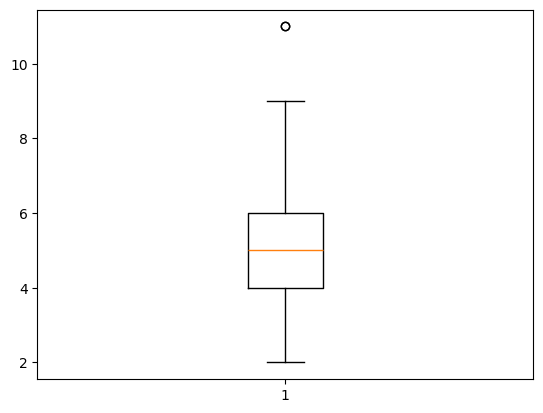

In [185]:
plt.boxplot(df[""])

In [184]:
df["Tenure_Months"]

15      18
17      33
23      67
57      33
99      49
148      1
152     89
188    101
212     29
215     24
241     12
258     77
262     15
284     20
313     53
342     96
348     31
377     35
393     73
394     36
407     60
466      7
468    117
543     26
545     83
648     49
660     30
661    109
677     32
733     23
735    103
736    119
766     63
800     68
801     37
812     58
824     63
849    112
900    112
913    114
956     88
992     52
Name: Tenure_Months, dtype: int64